<div align="center"><img src="https://github.com/user-attachments/assets/5d3a38ab-b20c-4103-b401-cddc112bfac8" width="300" alt="NOVA IMS Logo">

  <br>
  <br>
  <b>Master in Data Science and Advanced Analytics</b>

  <b>Computational Intelligence for Optimization </b>

  2025–2026

  <h1><b> Vermeer’s <i>Girl with a pearl earing</i>: 100 triangles Challenge <b></h1>
</div>



### <span style="color:#89AC76;">C22_Natural_Selection | Members</span>

<table>
  <thead style="color:#89AC76;">
    <tr>
      <th>Name</th>
      <th>Student ID</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Afonso Hermenegildo</td>
      <td>20221958</td>
    </tr>
    <tr>
      <td>André Ferreira</td>
      <td>20250398</td>
    </tr>
    <tr>
      <td>Marco Martins</td>
      <td>20221951</td>
    </tr>
    <tr>
      <td>Maria Francisca Gonçalves</td>
      <td>20221942</td>
    </tr>
  </tbody>
</table>

## <span style="color:#89AC76;">Table of Contents</span>


[ADICIONAR!!]

---
<h2 id="chapter1" style="color:#89AC76;">1. Imports</h2>
<p><a href="#toc" style="color:#89AC76;"> Back to Table of Contents</a></p>

All libraries used throughout the notebook are imported here. We rely on `Pillow` and `numpy` for image handling, `matplotlib` for visualisation, and `scipy` for statistical testing. The class-provided `library` module is also imported to access the base `Solution` class.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from triangle_sol import TriangleSolution
from ga import genetic_algorithm
from ga_utils import get_fitness
from experiments import (
    run_grid_search,
    print_grid_search_results,
    plot_grid_search_results,
    plot_fitness_history,
)
from operators import (
    # selection
    roulette_wheel_selection,
    rank_based_selection,
    tournament_selection,
    # crossover
    one_point_crossover,
    two_point_crossover,
    uniform_crossover,
    # mutation
    triangle_gaussian_mutation,
    triangle_color_mutation,
    triangle_vertex_mutation,
    triangle_level_mutation,
)

---
<h2 id="chapter2" style="color:#89AC76;">2. Target Image Loading &amp; Inspection</h2>
<p><a href="#toc" style="color:#89AC76;"> Back to Table of Contents</a></p>

We load the 300×400 target image and convert it to a NumPy array. Keeping the array in memory as a global constant avoids redundant I/O during fitness evaluations, which are called thousands of times per run.

Image size  : 300 x 400 px
Array shape : (400, 300, 3)


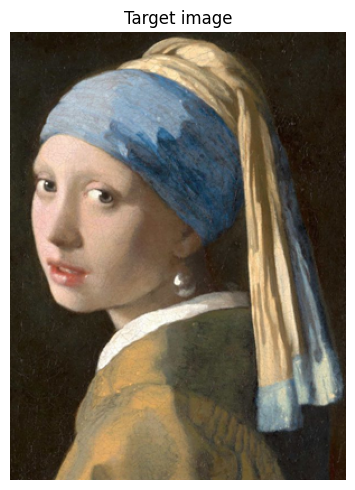

In [2]:
IMG_PATH = "girl_pearl_earing.png"   # adjust path if needed

target_img = Image.open(IMG_PATH).convert("RGB")
target_arr = np.array(target_img, dtype=np.int16)

IMG_WIDTH, IMG_HEIGHT = target_img.size   # (width, height) from PIL

print(f"Image size  : {IMG_WIDTH} x {IMG_HEIGHT} px")
print(f"Array shape : {target_arr.shape}")

# Wire the target into TriangleSolution so every instance uses it automatically
TriangleSolution.target_array = target_arr
TriangleSolution.__init__.__defaults__  # sanity-check defaults still present

plt.figure(figsize=(4, 5))
plt.imshow(target_arr)
plt.title("Target image")
plt.axis("off")
plt.tight_layout()
plt.show()

---
<h2 id="chapter3" style="color:#89AC76;">3. Solution Representation</h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

### Representation - How the solution is encoded

Each individual in the population encodes a candidate image as an ordered sequence of **100 triangles**, drawn sequentially onto a 300×400 canvas — later triangles occlude earlier ones. Each triangle is represented by **10 real-valued genes**.

```
[ x1, y1, x2, y2, x3, y3, Red, Green, Blue, Alpha]
```


| Gene(s) | Variable | Domain |
|---|---|---|
| x₁, y₁, x₂, y₂, x₃, y₃ | Vertex coordinates | [0, 1] (normalised) |
| R, G, B | Fill colour | [0, 255] |
| A | Opacity | [0, 255] |

### Fitness - measurement of quality of the solution
Fitness is the **pixel-wise RMSE** between the rendered image and the target (lower is  better, since this is a minimisation problem):

$$\text{RMSE} = \sqrt{\frac{1}{W \cdot H \cdot 4} \sum_{i,j,c} (\hat{I}_{ijc} - I_{ijc})^2}$$

where $W=300$, $H=400$, and $C=4$ (RGBA channels)


<span style="color:#BA8E23;">

**TEXT ABOVE INSPIRED IN PRATICAL CLASS 3**

</span>

In [ ]:
sol = TriangleSolution(
    n_triangles=N_TRIANGLES,
    img_width=IMG_WIDTH,
    img_height=IMG_HEIGHT,
    target_array=TARGET_ARRAY
)

NameError: name 'TARGET_ARRAY' is not defined

In [ ]:
sol.representation

array([293, 255, 137, 251, 237, 235,  31,   4, 229, 221, 177, 355, 290,
       184,  93, 333, 251,  99, 141, 165,  89, 303, 269, 294,  57, 149,
        55, 228, 242,  92, 123, 150,  92, 204, 200, 146,  41,  72, 157,
       244,  29, 233,  32, 240,  34, 372, 122,  26,   3, 176, 246, 310,
       225, 168, 159, 214,   2, 204, 120, 114, 158, 182, 194, 383, 188,
       120, 193, 229,  11, 170, 217, 247, 291, 368, 157, 183,  30,  72,
       171,  52,  26, 132, 226, 150,  97,  96, 112,  38, 192,   0,  21,
       314,  72, 135,  91, 335,  74, 162, 210, 231,   1, 169, 233, 339,
       257,  63, 209, 147, 123,  73, 115, 107,  25, 361,   7, 315,  17,
       248,  12,  55, 196,  28,  48, 126, 221, 187,  80, 191, 213, 220,
         7,  69, 203,  50,  87, 279, 149, 200, 215, 206, 189, 175,  89,
       368,  10,  38,  76, 104, 164,  98, 218, 282, 197, 325, 250, 140,
       215, 125,  61, 111,  49, 177, 285, 353, 188, 181, 131, 181,  71,
        56, 271, 181, 135, 124, 155, 151, 159, 226,  82,  69,  5

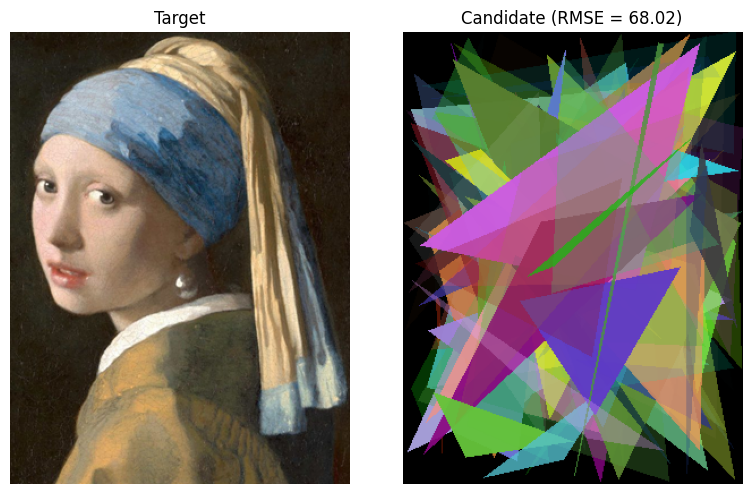

In [ ]:
sol.show()

The output generated is a **single random individual**.

<h2 id="chapter4" style="color:#89AC76;">4. Baseline GA Run</h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

A single run with sensible defaults to confirm everything works end-to-end.

In [ ]:
BASELINE_PARAMS = dict(
    population_size     = 50,
    n_generations       = 200,     # increase for better quality
    selection_method    = "rank",
    crossover_fn        = one_point_crossover,
    mutation_fn         = triangle_level_mutation,
    crossover_rate      = 0.9,
    mutation_rate       = 0.02,
    mutation_rate_decay = 0.0,
    sigma_vertex        = 20,      # pixel-scale (images are ~300x400)
    sigma_colour        = 20,
    elitism_n           = 2,
    n_jobs              = -1,
    verbose             = True,
    verbose_every       = 25,
)

best_sol, history, avg_history = genetic_algorithm(**BASELINE_PARAMS)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

<h3 id="chapter4.1" style="color:#89AC76;">4.1 Convergence Plot</h3>

In [ ]:
plot_fitness_history(
    history,
    avg_history,
    title=f"Baseline GA — best RMSE: {history[-1]:.4f}",
)

<h2 id="chapter4" style="color:#89AC76;">5. Best Candidate vs. Target </h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

In [ ]:
best_sol.show()

<h2 id="chapter4" style="color:#89AC76;">6. Custom Run - Swap Operators </h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

Try two-point crossover + tournament selection to compare.

In [ ]:
best_custom, hist_custom, avg_hist_custom = genetic_algorithm(
    population_size     = 50,
    n_generations       = 200,
    selection_method    = tournament_selection,
    crossover_fn        = two_point_crossover,
    mutation_fn         = triangle_level_mutation,
    crossover_rate      = 0.9,
    mutation_rate       = 0.02,
    sigma_vertex        = 20,
    sigma_colour        = 20,
    elitism_n           = 2,
    n_jobs              = -1,
    verbose             = True,
    verbose_every       = 25,
)

# Compare both runs
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(history,      label=f"Baseline (rank + 1pt XO)  RMSE={history[-1]:.4f}")
ax.plot(hist_custom,  label=f"Custom  (tourn + 2pt XO)  RMSE={hist_custom[-1]:.4f}")
ax.set_xlabel("Generation")
ax.set_ylabel("Best RMSE")
ax.set_title("Operator Comparison")
ax.legend()
plt.tight_layout()
plt.show()

## 7 · Grid Search (Optional — can be slow)

Set  to run. Reduce  /  for a quick test.

In [ ]:
RUN_GRID_SEARCH = False   # ← set True to run

GRID = {
    "population_size" : [30, 50],
    "mutation_rate"   : [0.01, 0.03],
    "crossover_rate"  : [0.8, 0.95],
}

FIXED = dict(
    selection_method    = "rank",
    crossover_fn        = one_point_crossover,
    mutation_fn         = triangle_level_mutation,
    mutation_rate_decay = 0.0,
    sigma_vertex        = 20,
    sigma_colour        = 20,
    elitism_n           = 2,
    verbose             = False,
)

GS_GENERATIONS = 100   # short run for the grid
GS_REPEATS     = 2

if RUN_GRID_SEARCH:
    gs_results = run_grid_search(
        grid         = GRID,
        gs_generations = GS_GENERATIONS,
        gs_repeats     = GS_REPEATS,
        fixed_params   = FIXED,
        n_jobs_ga      = 1,   # set -1 if you have many cores
    )
    print_grid_search_results(gs_results, top_n=8)
    plot_grid_search_results(gs_results, top_n=8)
else:
    print("Grid search skipped. Set RUN_GRID_SEARCH = True to run.")

<h2 id="chapter4" style="color:#89AC76;">8. Save Best Result </h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>


In [ ]:
out_path = "best_result.png"
best_sol.get_image().save(out_path)
print(f"Saved best candidate to: {out_path}")

<span style="color:#BA8E23;">

### <h2><strong>CONFIRM IF IS DONE - UPDATE MAIN</strong></h2>
1. **Hybrid GA + Local Search (Hill Climbing or CMA-ES) - ANDRÉ** - CONFIRMAR SE ESTÁ
	- ran Hill Climbing as a local search after the GA converged, using the GA's best solution as the starting point.

2. **Adaptive mutation - AFONSO**
Static mutation is a bottleneck.
Use:
	- high mutation early
	- low mutation late
	- per‑triangle mutation rates

3. **Multiple operators per category - MARCO** 
	- 3 selection methods (2 - WHICH IS APPLIED NOW !!)
	- 3 crossover operators (1)
	- 3 mutation operators (1)

### <h2><strong>TOP PRIORITY</strong></h2>
1. **Fitness sharing (diversity preservation)**
- a) **Distance function**
 L2 on raw repr. array (100 triangles x 10 genes = 1000-dim vector)np.linalg.norm(a - b <br>
- b) **Sharing function**
sh(d) = 1 - (d/sigma)^a ~
	if d < sigma, 
	else 0 a=1 is linear (simplest) sigma_share to tune 
- c) **Shared fitness** 
niche = sum(sh(d(i,j))) for all j in population shared_f = raw_f * niche selection uses shared_f <br>

### <h2><strong>MEDIUM PRIORITY</strong></h2>
1. **Smarter initialization**
- Sample triangle colours from target pixels
- Cuts early RMSE immediately

2. **Diversity measurement**
Track avg pairwise distance per gen
Diagnose when sharing is helping


### <h2><strong>ANALYSIS AND REPORTING </strong></h2>
1. **Wilcoxon statistical tests with a tournament structure**<br>
Use Wilcoxon signed-rank tests to determine which configuration was statistically significantly better, then ran a tournament-style elimination comparing the winner sequentially against challengers.

2. **Search space size**
Frame as continuous space
Show problem awareness


</span>